# 01 · Demand forecasting (branch × category × week)

**Business problem.** Branches run out of fast-moving items while warehouses hold stock (the *stockout paradox*).
To restock *before* that happens we need to know how many units each branch will sell of each category over the next weeks.

**Approach (deliberately simple):**
* One row per *branch × category × week* (80 × 16 = 1,280 series).
* One **HistGradientBoosting** model per horizon `h = 1…4` weeks ("direct" forecasting – no error build-up).
* **Poisson loss** because units are non-negative counts.
* Features: recent sales (lags, rolling means), last year's same week, branch & network trend, and the **Egyptian calendar of the target week** (Ramadan, Eid, Black Friday).
* **P10/P90 interval** from a negative-binomial using over-dispersion estimated on a validation window.
* Honest evaluation: **time-based split** (train → validation → last 13 weeks as test) against three naive baselines.

Outputs: `artifacts/models/demand_forecast.joblib`, `serving/forecast_latest.csv.gz`, `serving/weekly_history.csv.gz`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # lets the notebook import the `cottonil` package
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cottonil import config as cfg
from cottonil.data_io import load_table, load_sales_lines, load_product_master, week_start, quick_profile
from cottonil.plotting import setup, NAVY, TEAL, ORANGE, RED, PALETTE
setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

DATA_DIR = cfg.find_data_dir()
SOURCE = cfg.data_source(DATA_DIR)
print(f"Data folder : {DATA_DIR}")
print(f"Data source : {SOURCE.upper()}" + ("   <-- synthetic test data; retrain on real data before trusting any number" if SOURCE == "synthetic" else ""))

Data folder : D:\HVIA Internship\task 2\cottonil-ai\COTTONIL_Data
Data source : REAL


In [2]:
import time, joblib
from cottonil import forecast as F
lines = load_sales_lines()
branches = load_table("branches")
panel = F.make_panel(lines, branches)
U, weeks = panel["U"], panel["weeks"]
S, W = U.shape
print(f"{S} series (branch x category) x {W} weeks   [{weeks[0].date()} -> {weeks[-1].date()}]")
print(f"mean weekly units per active series: {U[panel['active']].mean():.1f} | share of zero weeks: {(U[panel['active']] == 0).mean():.1%}")

1280 series (branch x category) x 417 weeks   [2018-10-22 -> 2026-10-12]
mean weekly units per active series: 6.4 | share of zero weeks: 34.3%


## 1 · Look at the signal (does the calendar matter?)

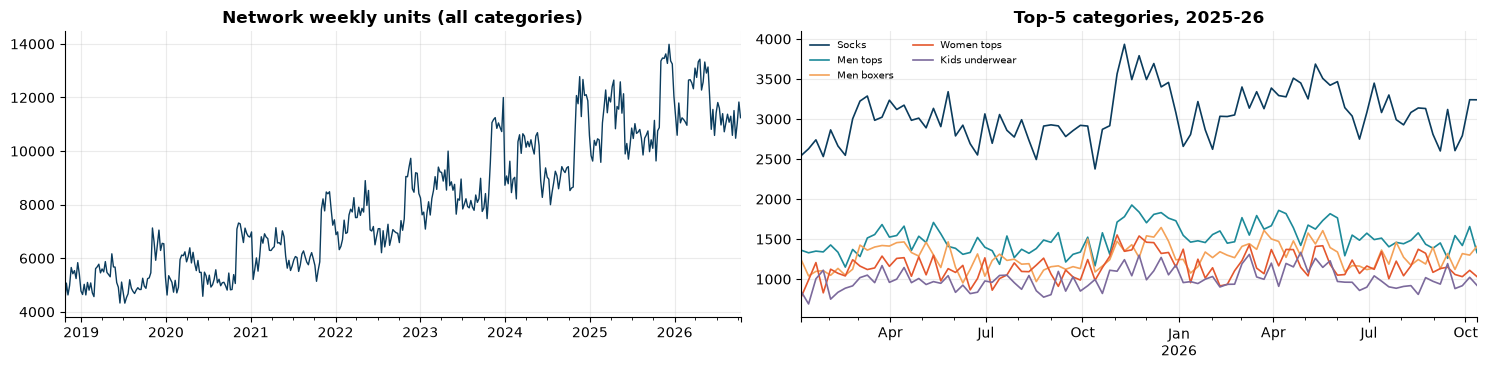

In [3]:
net = pd.DataFrame(U.reshape(panel["B"], panel["K"], W).sum(0).T, index=weeks, columns=panel["categories"])
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
net.sum(axis=1).plot(ax=ax[0], color=NAVY, lw=1); ax[0].set_title("Network weekly units (all categories)")
top = net.sum().sort_values(ascending=False).index[:5]
net.loc[net.index >= "2025-01-01", top].plot(ax=ax[1], lw=1.2); ax[1].set_title("Top-5 categories, 2025-26"); ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 2 · Time-based split
Splitting is by the **target week** so nothing from the future leaks into training:

| split | target weeks |
|---|---|
| train | everything up to 26 weeks before the end |
| validation | the 13 weeks before the test window (used to choose #trees and estimate interval width) |
| test | **last 13 weeks** (never touched until the final report) |

In [4]:
TEST_W, VAL_W = 13, 13
test_start, val_start = W - TEST_W, W - TEST_W - VAL_W
origins = np.arange(F.MIN_HISTORY_WEEKS - 1, W - 1)

data = {}
for h in F.HORIZONS:
    X, y, meta = F.build_features(panel, h, origins[origins + h <= W - 1])
    tgt = meta["w"].values + h
    data[h] = dict(X=X, y=y, meta=meta,
                   tr=tgt < val_start, va=(tgt >= val_start) & (tgt < test_start), te=tgt >= test_start)
d1 = data[1]
print("h=1 rows -> train %d | val %d | test %d | features: %d" % (d1["tr"].sum(), d1["va"].sum(), d1["te"].sum(), d1["X"].shape[1]))

h=1 rows -> train 467200 | val 16640 | test 16640 | features: 29


## 3 · Train one model per horizon
For each horizon we grow up to 300 trees on the *train* window and use `staged_predict` to pick the number of trees
with the lowest **validation Poisson deviance** (early stopping without peeking at test).

h=1: best #trees =  45  val deviance = 7.2999   (10s)


h=2: best #trees =  55  val deviance = 7.3245   (9s)


h=3: best #trees =  60  val deviance = 7.3159   (10s)


h=4: best #trees =  71  val deviance = 7.3120   (10s)


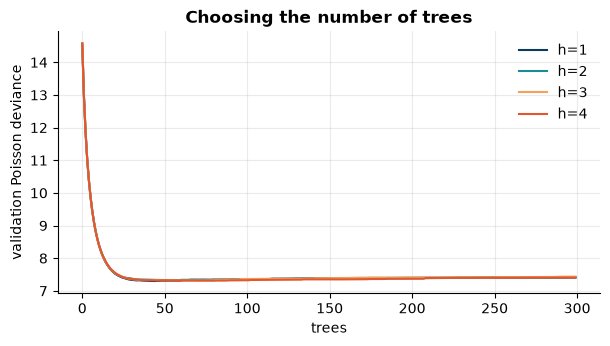

In [5]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_poisson_deviance

def new_model(n_iter):
    return HistGradientBoostingRegressor(loss="poisson", learning_rate=0.08, max_iter=n_iter, max_leaf_nodes=31,
                                         min_samples_leaf=40, l2_regularization=1.0, categorical_features=F.CAT_FEATURES,
                                         early_stopping=False, random_state=42)
def pois_dev(y, p):
    return mean_poisson_deviance(y, np.clip(p, 1e-3, None))

best_iter, val_curves, sel_models = {}, {}, {}
for h in F.HORIZONS:
    d = data[h]; t0 = time.time()
    m = new_model(300).fit(d["X"][d["tr"]], d["y"][d["tr"]])
    curve = [pois_dev(d["y"][d["va"]], p) for p in m.staged_predict(d["X"][d["va"]])]
    best_iter[h] = int(np.argmin(curve)) + 1
    val_curves[h], sel_models[h] = curve, m
    print(f"h={h}: best #trees = {best_iter[h]:3d}  val deviance = {min(curve):.4f}   ({time.time() - t0:.0f}s)")

plt.figure(figsize=(7, 3.4))
for h in F.HORIZONS: plt.plot(val_curves[h], label=f"h={h}")
plt.xlabel("trees"); plt.ylabel("validation Poisson deviance"); plt.legend(); plt.title("Choosing the number of trees"); plt.show()

## 4 · Evaluate on the untouched test window
Metrics: **WAPE** = Σ|actual − forecast| / Σ actual (lower is better) and **bias** = Σ forecast / Σ actual − 1.
Baselines: *naive* (this week repeats), *MA4* (4-week average), *seasonal naive* (same week last year).

In [6]:
def staged_at(model, X, k):
    for i, p in enumerate(model.staged_predict(X), 1):
        if i == k: return p

rows, preds_test = [], {}
for h in F.HORIZONS:
    d = data[h]; te = d["te"]; Xt, yt = d["X"][te], d["y"][te]
    p = staged_at(sel_models[h], Xt, best_iter[h]); preds_test[h] = p
    base = {"naive (last week)": Xt["lag0"].values, "MA4": Xt["m4"].values,
            "seasonal naive (last year)": np.where(np.isnan(Xt["ly_target"].values), Xt["m4"].values, Xt["ly_target"].values)}
    r = {"horizon (weeks)": h, "model WAPE": F.wape(yt, p), "model bias": F.bias(yt, p)}
    for k, v in base.items(): r[k + " WAPE"] = F.wape(yt, v)
    rows.append(r)
res = pd.DataFrame(rows).set_index("horizon (weeks)")
res.round(3)

,model WAPE,model bias,naive (last week) WAPE,MA4 WAPE,seasonal naive (last year) WAPE
horizon (weeks),,,,,
1,0.644,-0.008,0.888,0.729,0.878
2,0.648,0.005,0.883,0.729,0.878
3,0.651,0.010,0.888,0.728,0.878
4,0.649,0.004,0.881,0.727,0.878


In [7]:
# Series-level numbers are noisy because each branch sells only a few units/week of some categories.
# Planners mostly look at totals, so also report accuracy once aggregated:
agg = []
for h in F.HORIZONS:
    d = data[h]; te = d["te"]
    df = d["meta"][te].copy(); df["y"] = d["y"][te]; df["p"] = preds_test[h]
    df["b"] = panel["series"]["branch_code"].values[df.s]; df["c"] = panel["series"]["category_code"].values[df.s]
    for lvl, keys in {"branch x week": ["b", "w"], "category x week": ["c", "w"], "network x week": ["w"]}.items():
        g = df.groupby(keys)[["y", "p"]].sum()
        agg.append({"horizon": h, "level": lvl, "WAPE": F.wape(g.y, g.p)})
agg = pd.DataFrame(agg).pivot(index="level", columns="horizon", values="WAPE").round(3)
agg

horizon,1,2,3,4
level,,,,
branch x week,0.283,0.286,0.287,0.286
category x week,0.095,0.096,0.098,0.097
network x week,0.031,0.026,0.028,0.026


**Reading the tables.** If *model WAPE* is below the best baseline at every horizon the model is adding value.
Accuracy improves sharply with aggregation (law of large numbers) – so use branch-level numbers for
*restock quantities* and network/category numbers for *production planning*.

## 5 · Prediction intervals (P10–P90)

In [8]:
phi = {}
for h in F.HORIZONS:
    d = data[h]; va = d["va"]
    mu_va = staged_at(sel_models[h], d["X"][va], best_iter[h])
    phi[h] = F.estimate_overdispersion(d["y"][va], mu_va)
cov = []
for h in F.HORIZONS:
    d = data[h]; te = d["te"]; mu = preds_test[h]; y = d["y"][te]
    lo, hi = F.nb_quantile(mu, phi[h], .10), F.nb_quantile(mu, phi[h], .90)
    cov.append({"horizon": h, "phi (overdispersion)": round(phi[h], 3), "coverage of P10-P90 (target ~80%)": float(((y >= lo) & (y <= hi)).mean()),
                "share above P90 (target ~10%)": float((y > hi).mean())})
pd.DataFrame(cov).set_index("horizon").round(3)

,phi (overdispersion),coverage of P10-P90 (target ~80%),share above P90 (target ~10%)
horizon,,,
1,0.667,0.872,0.089
2,0.664,0.872,0.089
3,0.653,0.869,0.089
4,0.651,0.867,0.091


## 6 · Final fit on ALL data and save
Now that the design is validated, refit each horizon on *every* available week (train + val + test) with the chosen number of trees.

In [9]:
final = {}
for h in F.HORIZONS:
    d = data[h]; t0 = time.time()
    final[h] = new_model(best_iter[h]).fit(d["X"], d["y"])
    print(f"final model h={h} fitted on {len(d['X']):,} rows ({time.time() - t0:.0f}s)")

bundle = {"models": final, "features": F.feature_names(), "phi": phi, "best_iter": best_iter,
          "as_of_week": str(weeks[-1].date()), "categories": panel["categories"], "branch_ids": panel["branch_ids"],
          "data_source": SOURCE}
cfg.save_model("demand_forecast", bundle)

fl = F.latest_forecast(bundle, panel)
fl["week_start"] = fl["week_start"].dt.strftime("%Y-%m-%d")
cfg.save_serving("forecast_latest", fl.round(2))

hist = pd.DataFrame(U[:, -78:].T, index=weeks[-78:], columns=pd.MultiIndex.from_frame(panel["series"][["branch_id", "category"]]))
hist = hist.stack(["branch_id", "category"]).rename("units").reset_index().rename(columns={"level_0": "week_start"})
hist.columns = ["week_start", "branch_id", "category", "units"]
hist["week_start"] = hist["week_start"].dt.strftime("%Y-%m-%d")
net_all = net.loc[net.index >= weeks[-1] - pd.Timedelta(days=7 * 400)].stack().rename("units").reset_index()
net_all.columns = ["week_start", "category", "units"]; net_all["week_start"] = net_all["week_start"].dt.strftime("%Y-%m-%d")
net_all.insert(1, "branch_id", "ALL")
cfg.save_serving("weekly_history", pd.concat([hist, net_all], ignore_index=True))

summary = {"test_wape_by_horizon": res["model WAPE"].round(4).to_dict(),
           "best_baseline_wape_by_horizon": res[[c for c in res.columns if c.endswith("WAPE") and c != "model WAPE"]].min(axis=1).round(4).to_dict(),
           "aggregated_wape": agg.to_dict(), "interval_coverage": {int(r["horizon"]): r["coverage of P10-P90 (target ~80%)"] for r in cov},
           "n_series": S, "n_weeks": W, "as_of_week": str(weeks[-1].date()), "best_iter": best_iter}
cfg.save_metrics("01_demand_forecast", summary, DATA_DIR)
fl.head()

final model h=1 fitted on 500,480 rows (3s)


final model h=2 fitted on 499,200 rows (3s)


final model h=3 fitted on 497,920 rows (3s)


final model h=4 fitted on 496,640 rows (4s)


,branch_id,category,horizon,week_start,mean,p10,p90
0,BR001,Accessories,1,2026-10-19,1.268024,0.0,3.0
1,BR001,Boys pajamas,1,2026-10-19,6.193601,1.0,14.0
2,BR001,Girls pajamas,1,2026-10-19,6.817859,1.0,15.0
3,BR001,Girls underwear,1,2026-10-19,1.656238,0.0,4.0
4,BR001,Home textiles,1,2026-10-19,4.127299,0.0,9.0


## 7 · Round-trip check (what production will do)
Reload the saved bundle from disk, rebuild features from the raw panel and confirm we get the same forecast.

reloaded model reproduces the forecast: True


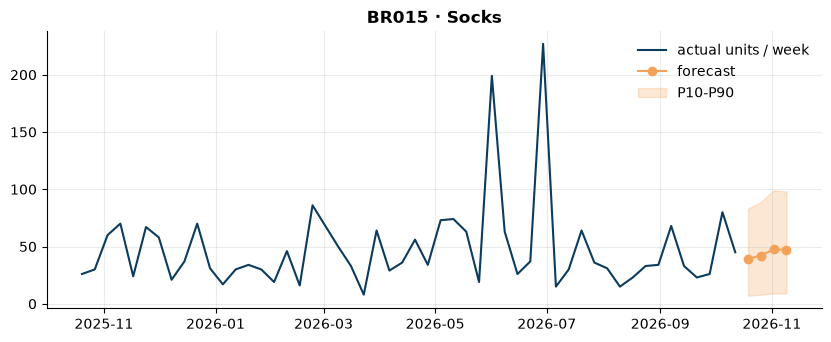

In [10]:
b2 = cfg.load_model("demand_forecast")
chk = F.latest_forecast(b2, panel)
chk["week_start"] = chk["week_start"].dt.strftime("%Y-%m-%d")
same = np.allclose(chk["mean"].values, F.latest_forecast(bundle, panel)["mean"].values)
print("reloaded model reproduces the forecast:", same)
assert same

# example: the busiest series, history + 4-week forecast with the P10-P90 band
s_top = int(np.argmax(U[:, -26:].sum(1)))
sid = panel["series"].iloc[s_top]
f_one = fl[(fl.branch_id == sid.branch_id) & (fl.category == sid.category)]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(weeks[-52:], U[s_top, -52:], color=NAVY, label="actual units / week")
fw = pd.to_datetime(f_one.week_start)
ax.plot(fw, f_one["mean"], color=ORANGE, marker="o", label="forecast"); ax.fill_between(fw, f_one.p10, f_one.p90, color=ORANGE, alpha=.25, label="P10-P90")
ax.set_title(f"{sid.branch_id} · {sid.category}"); ax.legend(); plt.show()

## Takeaways
* Model beats naive baselines on the held-out 13 weeks (see table) – *when run on the synthetic data this only proves the pipeline works*; re-run on real data for real accuracy.
* Aggregated forecasts are far more accurate than single branch × category forecasts – use that when explaining accuracy to the business.
* Next: `02_stockout_and_restock.ipynb` turns these forecasts + current stock into a restock plan.